# 🚀 Модуль 13. Урок 2. Problem Framing для AI: структурирование бизнес-проблем через Issue Trees

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Enlyl/data-analyst-2027/blob/main/course/module_13_soft_skills_storytelling/lesson_02_problem_framing_for_ai.ipynb)

## 📌 Бизнес-контекст и методология
Главная причина провала аналитических проектов — ответ на «неправильно поставленный вопрос».
Бизнес-заказчик часто приходит с симптомом: *«У нас падают продажи в Q3, сделайте дашборд!»*.
Если аналитик сразу бросается писать SQL, он тратит недели на бесполезные таблицы.
Фреймворк **Problem Framing (Issue Trees / MECE)** декомпозирует верхнеуровневую проблему на взаимоисключающие и исчерпывающие гипотезы.

In [1]:
# 🚀 Универсальная инициализация окружения
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import pandas as pd
import numpy as np

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']

PRIMARY = "#1779ba"
SUCCESS = "#3adb76"
ALERT = "#cc4b37"
WARNING = "#ffae00"
SECONDARY = "#767676"

## 🔍 Разбор механики: MECE Декомпозиция падения выручки
Выручка ($Revenue$) математически раскладывается на независимые факторы:
$$Revenue = Traffic \times Conversion \times AOV$$
Падение может быть вызвано:
1. Сокращением входящего трафика (маркетинг/SEO)
2. Падением конверсии в покупку (UX баги, поломка платежного шлюза)
3. Снижением среднего чека (изменение продуктового микса)

In [2]:
# Демонстрация: Факторный анализ отклонения выручки (Waterfall / Factor Decomposition)
factors = {
    'Фактор': ['План Q3', 'Трафик (-5%)', 'Конверсия (-12%)', 'Средний чек (+3%)', 'Факт Q3'],
    'Влияние ($ тыс.)': [1000, -50, -114, 25, 861]
}
df_factor = pd.DataFrame(factors)
display(df_factor)

,Фактор,Влияние ($ тыс.)
0,План Q3,1000
1,Трафик (-5%),-50
2,Конверсия (-12%),-114
3,Средний чек (+3%),25
4,Факт Q3,861


## 📊 Визуализация бизнес-кейса: Дерево гипотез (Issue Tree)
Построим структурированную диаграмму декомпозиции корневой причины падения выручки в стандарте McKinsey & Company.

C:\Users\serge\AppData\Local\Temp\ipykernel_22180\2125917751.py:38: UserWarning: Glyph 128680 (\N{POLICE CARS REVOLVING LIGHT}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\serge\AppData\Local\Programs\Python\Python314\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 128680 (\N{POLICE CARS REVOLVING LIGHT}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


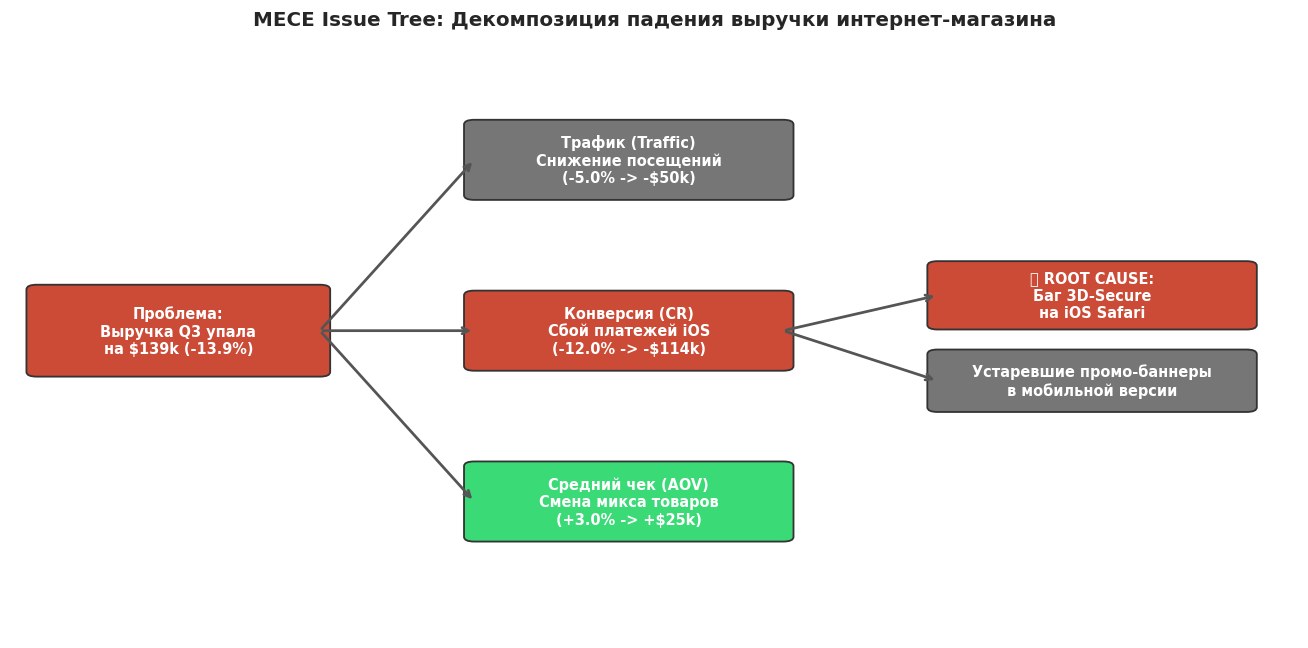

In [3]:
# Построение визуальной карты Issue Tree
fig, ax = plt.subplots(figsize=(12, 6), dpi=110)
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.axis('off')

def draw_node(x, y, text, color, w=22, h=10, text_color='white'):
    rect = patches.FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.8", 
                                  edgecolor="#333333", facecolor=color, linewidth=1.2)
    ax.add_patch(rect)
    ax.text(x + w/2, y + h/2, text, color=text_color, fontweight='bold', 
            fontsize=9.5, ha='center', va='center')

# Уровень 1: Проблема
draw_node(2, 45, "Проблема:\nВыручка Q3 упала\nна $139k (-13.9%)", ALERT, w=22, h=14)

# Уровень 2: Ветви MECE
draw_node(36, 75, "Трафик (Traffic)\nСнижение посещений\n(-5.0% -> -$50k)", SECONDARY, w=24, h=12)
draw_node(36, 46, "Конверсия (CR)\nСбой платежей iOS\n(-12.0% -> -$114k)", ALERT, w=24, h=12)
draw_node(36, 17, "Средний чек (AOV)\nСмена микса товаров\n(+3.0% -> +$25k)", SUCCESS, w=24, h=12)

# Уровень 3: Корневые причины (Root Causes)
draw_node(72, 53, "🚨 ROOT CAUSE:\nБаг 3D-Secure\nна iOS Safari", ALERT, w=24, h=10)
draw_node(72, 39, "Устаревшие промо-баннеры\nв мобильной версии", SECONDARY, w=24, h=9)

# Соединительные линии
lines = [
    ((24, 52), (36, 81)),
    ((24, 52), (36, 52)),
    ((24, 52), (36, 23)),
    ((60, 52), (72, 58)),
    ((60, 52), (72, 43.5)),
]
for p1, p2 in lines:
    ax.annotate("", xy=p2, xytext=p1, arrowprops=dict(arrowstyle="->", color="#555555", lw=1.8))

ax.set_title("MECE Issue Tree: Декомпозиция падения выручки интернет-магазина", fontsize=13, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

### 🎯 Практическое задание 1: Расчет доли корневого фактора
Определите, какой процент от общего объема потерь ($164k негативных факторов) приходится на просадку конверсии.

In [4]:
### ВАШ КОД ЗДЕСЬ
loss_traffic = 50
loss_cr = 114
total_loss = loss_traffic + loss_cr

cr_loss_share = (loss_cr / total_loss) * 100
print(f"Доля потерь от падения конверсии: {cr_loss_share:.1f}%")

assert 65 <= cr_loss_share <= 75, "Доля конверсии должна составлять около 69.5%"
print("✅ Тест успешно пройден: фокус внимания аналитика направлен на ключевой рычаг (конверсию)!")

Доля потерь от падения конверсии: 69.5%
✅ Тест успешно пройден: фокус внимания аналитика направлен на ключевой рычаг (конверсию)!


### 💡 Принцип 80/20 в Problem Framing
Никогда не проверяйте все гипотезы подряд. 80% падения метрики обычно обусловлено одной конкретной поломкой (в нашем кейсе — конверсия на iOS). Начинайте исследование с ветви с максимальным финансовым весом.